## Reading matrices

In [3]:
'''Класс для чтения матриц и преобразования потоков'''
class MatrixLoader:
    def __init__(self, filepath='flavor_matrix.npz'):
        self.filepath = filepath
        self.data = None
        self.time = None
        self.energy = None
        self._load_data()

    def _load_data(self):
        self.data = np.load(self.filepath)
        self.time = self.data['T'] << u.s
        self.energy = self.data['E'] << u.MeV

    def get_matrix(self, angle, hierarchy): # получение матрицы
        array = self.data[f'M_{angle}_{hierarchy}']
        return FlavorMatrix(array=array, flavor=ThreeFlavor)

    def get_time(self): # получение временных бинов
        return self.time

    def get_energy(self): # получение энергетических бинов
        return self.energy
        
    def apply_to_flux(self, matrix, model=ccsn.Bollig_2016(progenitor_mass=27<<u.Msun), distance=10): #преобразование потока
        M = matrix
        flux = model.get_flux(self.time, self.energy, distance=distance*u.kpc)
        transformed_flux = (M @ flux)
        return transformed_flux
    

FlavorMatrix:<ThreeFlavor->ThreeFlavor> shape=(6, 6, 1, 800)


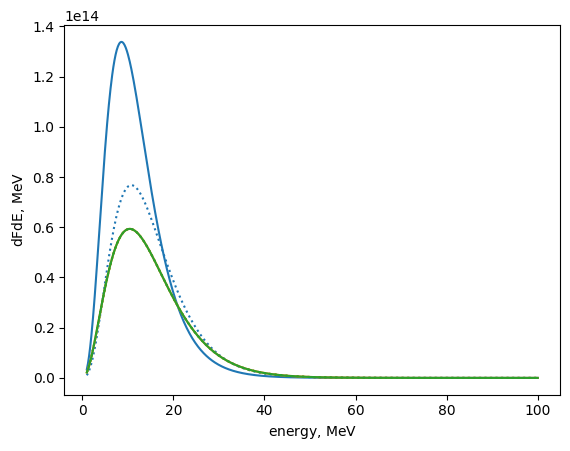

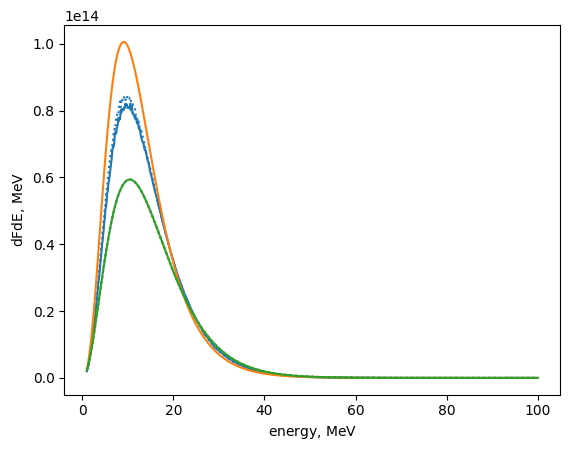

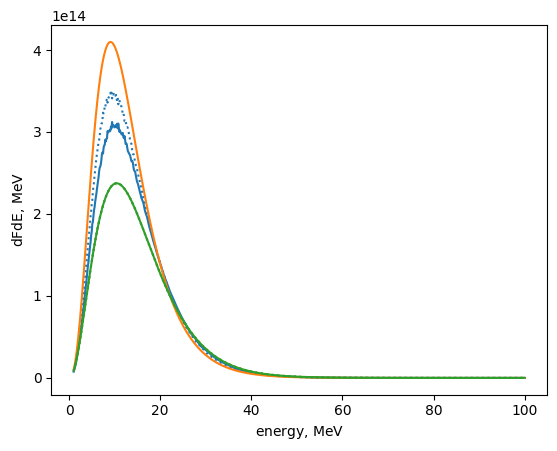

In [4]:
"""
Демонстрационная программа для класса MatrixLoader
Показывает:
1. Загрузку матриц из файла
2. Получение конкретных матриц
3. Применение матриц к потоку нейтрино
4. Визуализацию результатов
"""

import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from snewpy.flavor import FlavorMatrix, ThreeFlavor
from snewpy.models import ccsn

loader = MatrixLoader('flavor_matrix.npz') #создание загрузчика
keys = [k for k in loader.data.keys() if k.startswith('M_')] #список доступных матриц
'''
print(f"Доступные матрицы ({len(keys)} шт.):")
for key in keys:
    print(f"{key}") # key - название доступной матрицы
'''

M_norm = loader.get_matrix(angle=-90, hierarchy='NORMAL') #получение матриц
time = loader.get_time() #получение временных бинов
energy = loader.get_energy() #получение энергетических бинов
print(M_norm)
#print(time)

model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
flux = model.get_flux(time, energy, distance=10*u.kpc) # базовый поток (без трансформации)
flux_norm = loader.apply_to_flux(M_norm) # трансформированный поток (NORMAL)
flux_inv = loader.apply_to_flux(matrix=loader.get_matrix(angle=-90, hierarchy='INVERTED'), distance=5) # трансформированный поток (INVERTED)

flux.plot()
plt.show()
flux_norm.plot()
plt.show()
flux_inv.plot()
plt.show()